# ChronoClone Validation Under Noise

This notebook runs the ChronoClone metacloning validation pipeline on noised datasets (Normal, Uniform, and Combined) to evaluate the robustness of the algorithm to technical noise.

We measure the accuracy by comparing the calculated metaclones against the ground-truth labels using the **Adjusted Rand Index (ARI)** (where 1.0 represents perfect recovery of the original metaclones).


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
from anndata import AnnData
import chronoclone as cc
from sklearn.metrics import adjusted_rand_score
import time

# Predefined validation functions imported from chronoclone package
from chronoclone import (
    load_all_noise_data,
    load_combined_noise_data,
    run_chronoclone_validation
)

# =========================================================
# Configuration
# =========================================================

STANDARD_DIR = 'simulated_data/Standard'
ALL_NOISE_DIR = 'simulated_data/All_Noise'
COMBINED_NOISE_DIR = 'simulated_data/Combined_Noise'

time_cols = ['0', '4', '9', '15']
DAYS_CTRL = ['Day0', 'Day4', 'Day9', 'Day15']
pop = ['HSC', 'HSPC', 'MEP', 'CMP', 'Mk_prog', 'MEMP',
       'GMP', 'GMDP', 'Mast_prog', 'Baso_prog', 'Neu_prog', 'DC_prog', 'Mono_prog']
vec = ['Day' + j + '_Cluster' + i for i in pop for j in time_cols]

print("Setup completed. Pop size:", len(pop), "Timepoints:", len(time_cols))


Setup completed. Pop size: 13 Timepoints: 4


## Helper Functions & Core Optimizations

All core pipeline steps (including vectorized clone table expansion, vectorized normalization, vectorized consensus matrix construction, and cached threshold sweeping) are defined inside the `chronoclone` package directory.

The noise simulation loading and validation loops are defined in `chronoclone/validation.py` and imported directly above. This ensures the notebook remains clean, robust, and completely aligned with the package's APIs for publication readiness.


## Single Noise Accuracy Sweeps

First, we will load files in `All_Noise` and show the accuracy for single noise:
1. Normal (Gaussian) noise with no Uniform noise (Uniform = 0%).
2. Uniform noise with no Normal noise (Normal = 0%).

We sample every 10% from 0% to 100% to evaluate the trends rapidly.


In [ ]:
# Levels: 0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100 (11 levels)
levels = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100]

print("=== Running Normal Noise Sweeps (0% Uniform) ===")
normal_ari = []
for pct in levels:
    t0 = time.time()
    final_table = load_all_noise_data(pct, 'gaussian')
    ari = run_chronoclone_validation(final_table)
    normal_ari.append(ari)
    print(f"  Normal noise {pct}%: ARI = {ari:.4f} (took {time.time()-t0:.2f} s)")

print("\n=== Running Uniform Noise Sweeps (0% Normal) ===")
uniform_ari = []
for pct in levels:
    t0 = time.time()
    final_table = load_all_noise_data(pct, 'uniform')
    ari = run_chronoclone_validation(final_table)
    uniform_ari.append(ari)
    print(f"  Uniform noise {pct}%: ARI = {ari:.4f} (took {time.time()-t0:.2f} s)")


=== Running Normal Noise Sweeps (0% Uniform) ===


2026-06-25 15:32:15.662234: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-06-25 15:32:15.703938: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


2026-06-25 15:32:18.169226: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


  Normal noise 0%: ARI = 1.0000 (took 12.82 s)


  Normal noise 10%: ARI = 1.0000 (took 1.16 s)


  Normal noise 20%: ARI = 0.9948 (took 1.16 s)


... (15 outputs left out)

  Uniform noise 70%: ARI = 0.6240 (took 1.78 s)


  Uniform noise 80%: ARI = 0.4258 (took 1.99 s)


  Uniform noise 90%: ARI = 0.2767 (took 2.03 s)


  Uniform noise 100%: ARI = 0.0632 (took 2.35 s)


## Plotting Single Noise Robustness

We will display two separate dot-line plots showing how the Adjusted Rand Index changes with the noise level.


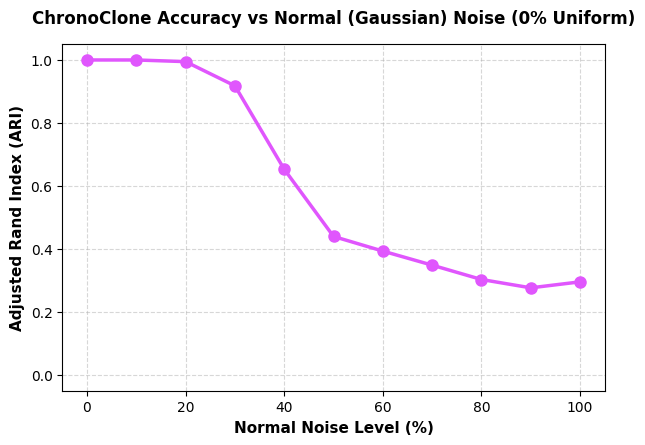

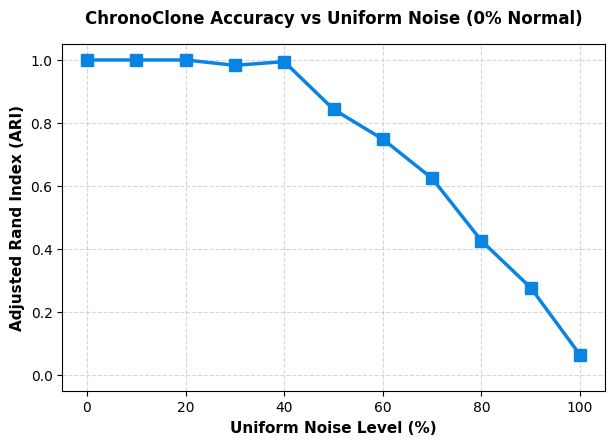

In [4]:
# Plot 1: Normal Noise vs ARI
plt.figure(figsize=(7, 4.5))
plt.plot(levels, normal_ari, marker='o', linestyle='-', color='#e056fd', linewidth=2.5, markersize=8)
plt.xlabel("Normal Noise Level (%)", fontsize=11, fontweight='bold')
plt.ylabel("Adjusted Rand Index (ARI)", fontsize=11, fontweight='bold')
plt.title("ChronoClone Accuracy vs Normal (Gaussian) Noise (0% Uniform)", fontsize=12, fontweight='bold', pad=15)
plt.grid(True, linestyle='--', alpha=0.5)
plt.ylim(-0.05, 1.05)
plt.show()

# Plot 2: Uniform Noise vs ARI
plt.figure(figsize=(7, 4.5))
plt.plot(levels, uniform_ari, marker='s', linestyle='-', color='#0984e3', linewidth=2.5, markersize=8)
plt.xlabel("Uniform Noise Level (%)", fontsize=11, fontweight='bold')
plt.ylabel("Adjusted Rand Index (ARI)", fontsize=11, fontweight='bold')
plt.title("ChronoClone Accuracy vs Uniform Noise (0% Normal)", fontsize=12, fontweight='bold', pad=15)
plt.grid(True, linestyle='--', alpha=0.5)
plt.ylim(-0.05, 1.05)
plt.show()


## Combined Noise Grid Evaluation

Now we will sweep a grid of combined noise (Normal $\times$ Uniform). To manage computation times, we will sweep the grid in 20% increments (0%, 20%, 40%, 60%, 80%, 100%), yielding a $6 \times 6$ matrix of combinations.


In [5]:
grid_levels = [0, 20, 40, 60, 80, 100]

print("=== Running Combined Noise Grid Validation ===")
combined_grid = np.zeros((len(grid_levels), len(grid_levels)))

for i, g_pct in enumerate(grid_levels):
    for j, u_pct in enumerate(grid_levels):
        t0 = time.time()
        final_table = load_combined_noise_data(g_pct, u_pct)
        ari = run_chronoclone_validation(final_table)
        combined_grid[i, j] = ari
        print(f"  Grid [Normal={g_pct}%, Uniform={u_pct}%]: ARI = {ari:.4f} (took {time.time()-t0:.2f} s)")


=== Running Combined Noise Grid Validation ===


  Grid [Normal=0%, Uniform=0%]: ARI = 1.0000 (took 1.01 s)


  Grid [Normal=0%, Uniform=20%]: ARI = 1.0000 (took 1.27 s)


  Grid [Normal=0%, Uniform=40%]: ARI = 0.9901 (took 1.33 s)


  Grid [Normal=0%, Uniform=60%]: ARI = 0.7773 (took 1.62 s)


  Grid [Normal=0%, Uniform=80%]: ARI = 0.4223 (took 1.94 s)


... (27 outputs left out)

  Grid [Normal=100%, Uniform=40%]: ARI = 0.2650 (took 1.86 s)


  Grid [Normal=100%, Uniform=60%]: ARI = 0.2705 (took 1.85 s)


  Grid [Normal=100%, Uniform=80%]: ARI = 0.1976 (took 1.89 s)


  Grid [Normal=100%, Uniform=100%]: ARI = 0.0751 (took 1.86 s)


## Combined Noise Robustness Heatmap

Plotting the performance grid as a heatmap to evaluate the boundaries of noise tolerance.


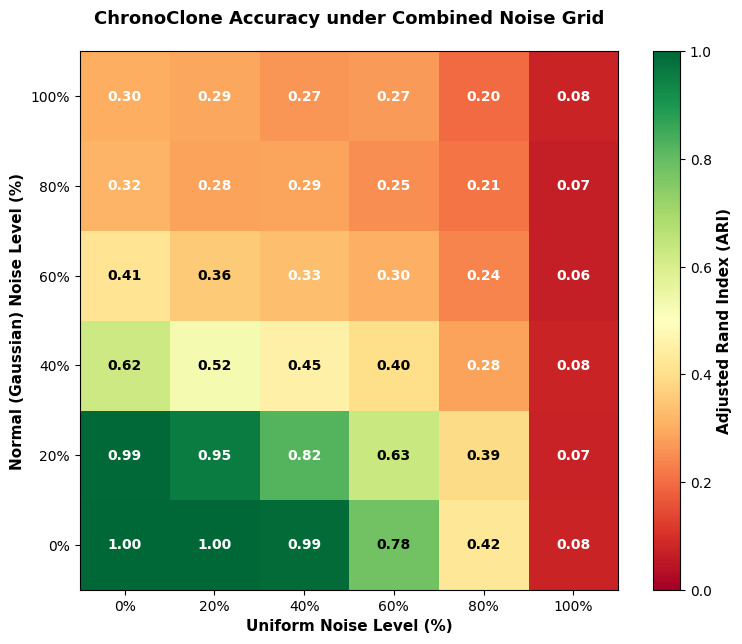

In [6]:
plt.figure(figsize=(8, 6.5))
im = plt.imshow(combined_grid, cmap='RdYlGn', origin='lower', vmin=0, vmax=1)
cbar = plt.colorbar(im)
cbar.set_label("Adjusted Rand Index (ARI)", fontsize=11, fontweight='bold')

plt.xticks(range(len(grid_levels)), [f"{x}%" for x in grid_levels])
plt.yticks(range(len(grid_levels)), [f"{x}%" for x in grid_levels])
plt.xlabel("Uniform Noise Level (%)", fontsize=11, fontweight='bold')
plt.ylabel("Normal (Gaussian) Noise Level (%)", fontsize=11, fontweight='bold')
plt.title("ChronoClone Accuracy under Combined Noise Grid", fontsize=13, fontweight='bold', pad=20)

# Annotate values inside cells
for i in range(len(grid_levels)):
    for j in range(len(grid_levels)):
        val = combined_grid[i, j]
        # Text color is black for middle values, white for extreme colors
        text_color = "white" if val < 0.35 or val > 0.8 else "black"
        plt.text(j, i, f"{val:.2f}", ha="center", va="center", 
                 color=text_color, fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

## Full Single Noise Sweeps (Every 2%)

Running ChronoClone validation at every 2% noise level (0%, 2%, 4%, ..., 100%) for both Normal and Uniform noise independently.


In [7]:
all_levels = list(range(0, 101, 2))  # 51 levels

print("=== Full Normal Noise Sweep (every 2%, 0% Uniform) ===")
full_normal_ari = []
for pct in all_levels:
    t0 = time.time()
    ft = load_all_noise_data(pct, 'gaussian')
    ari = run_chronoclone_validation(ft)
    full_normal_ari.append(ari)
    print(f"  Normal {pct}%: ARI = {ari:.4f} ({time.time()-t0:.1f}s)")

print("\n=== Full Uniform Noise Sweep (every 2%, 0% Normal) ===")
full_uniform_ari = []
for pct in all_levels:
    t0 = time.time()
    ft = load_all_noise_data(pct, 'uniform')
    ari = run_chronoclone_validation(ft)
    full_uniform_ari.append(ari)
    print(f"  Uniform {pct}%: ARI = {ari:.4f} ({time.time()-t0:.1f}s)")


=== Full Normal Noise Sweep (every 2%, 0% Uniform) ===


  Normal 0%: ARI = 1.0000 (1.0s)


  Normal 2%: ARI = 1.0000 (1.3s)


  Normal 4%: ARI = 1.0000 (1.2s)


  Normal 6%: ARI = 1.0000 (1.2s)


  Normal 8%: ARI = 1.0000 (1.2s)


... (93 outputs left out)

  Uniform 94%: ARI = 0.1961 (2.3s)


  Uniform 96%: ARI = 0.1254 (2.2s)


  Uniform 98%: ARI = 0.0795 (2.3s)


  Uniform 100%: ARI = 0.0632 (2.4s)


### Full Single Noise Plots (Every 2%)


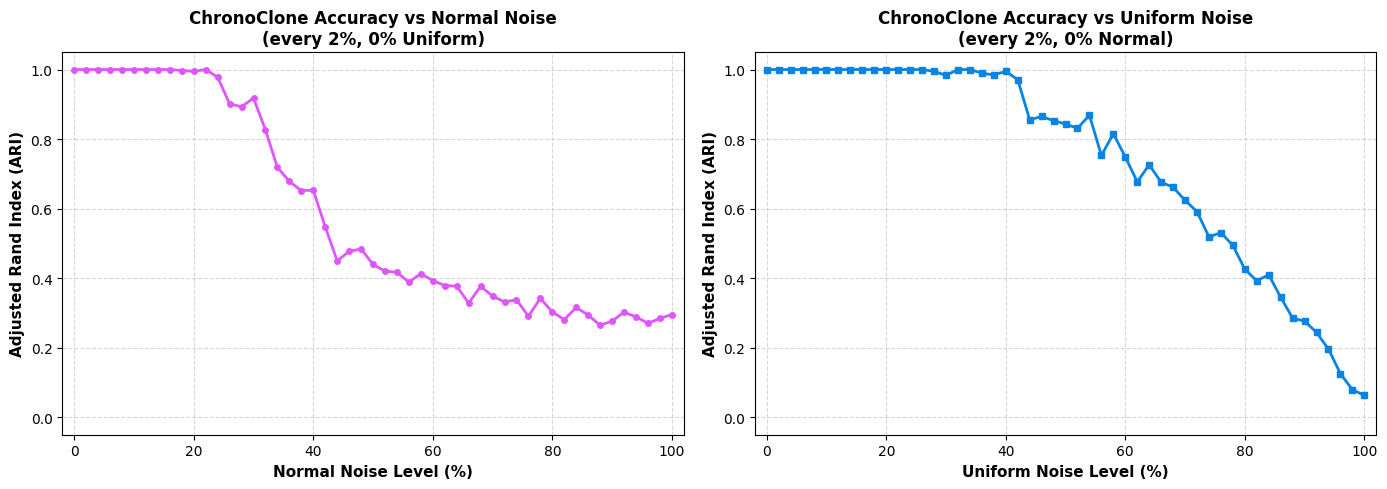

In [8]:
# Plot 1: Full Normal Noise vs ARI
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(all_levels, full_normal_ari, marker='o', linestyle='-', color='#e056fd', linewidth=2, markersize=4)
axes[0].set_xlabel("Normal Noise Level (%)", fontsize=11, fontweight='bold')
axes[0].set_ylabel("Adjusted Rand Index (ARI)", fontsize=11, fontweight='bold')
axes[0].set_title("ChronoClone Accuracy vs Normal Noise\n(every 2%, 0% Uniform)", fontsize=12, fontweight='bold')
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].set_ylim(-0.05, 1.05)
axes[0].set_xlim(-2, 102)

# Plot 2: Full Uniform Noise vs ARI
axes[1].plot(all_levels, full_uniform_ari, marker='s', linestyle='-', color='#0984e3', linewidth=2, markersize=4)
axes[1].set_xlabel("Uniform Noise Level (%)", fontsize=11, fontweight='bold')
axes[1].set_ylabel("Adjusted Rand Index (ARI)", fontsize=11, fontweight='bold')
axes[1].set_title("ChronoClone Accuracy vs Uniform Noise\n(every 2%, 0% Normal)", fontsize=12, fontweight='bold')
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].set_ylim(-0.05, 1.05)
axes[1].set_xlim(-2, 102)

plt.tight_layout()
plt.show()


## Full Combined Noise Grid (Every 2%)

Running ChronoClone validation at every 2% noise level for both Normal and Uniform noise simultaneously.
This creates a $51 \times 51 = 2601$ grid of evaluations.

> **Note:** This cell takes several hours to execute (~5 hours at ~7s per evaluation).


In [9]:
all_levels_combined = list(range(0, 101, 2))  # 51 levels
n = len(all_levels_combined)

print(f"=== Full Combined Noise Grid ({n}x{n} = {n*n} evaluations) ===")
full_combined_grid = np.zeros((n, n))

total_runs = n * n
run_count = 0

for i, g_pct in enumerate(all_levels_combined):
    for j, u_pct in enumerate(all_levels_combined):
        t0 = time.time()
        ft = load_combined_noise_data(g_pct, u_pct)
        ari = run_chronoclone_validation(ft)
        full_combined_grid[i, j] = ari
        run_count += 1
        if run_count % 51 == 0 or run_count <= 3:
            elapsed = time.time() - t0
            print(f"  [{run_count}/{total_runs}] Normal={g_pct}%, Uniform={u_pct}%: ARI={ari:.4f} ({elapsed:.1f}s)")

print(f"\nAll {total_runs} evaluations complete!")


=== Full Combined Noise Grid (51x51 = 2601 evaluations) ===


  [1/2601] Normal=0%, Uniform=0%: ARI=1.0000 (1.0s)


  [2/2601] Normal=0%, Uniform=2%: ARI=1.0000 (1.2s)


  [3/2601] Normal=0%, Uniform=4%: ARI=1.0000 (1.3s)


  [51/2601] Normal=0%, Uniform=100%: ARI=0.0761 (2.4s)


  [102/2601] Normal=2%, Uniform=100%: ARI=0.0699 (2.5s)


... (45 outputs left out)

  [2448/2601] Normal=94%, Uniform=100%: ARI=0.0694 (2.1s)


  [2499/2601] Normal=96%, Uniform=100%: ARI=0.0663 (2.1s)


  [2550/2601] Normal=98%, Uniform=100%: ARI=0.0571 (2.0s)


  [2601/2601] Normal=100%, Uniform=100%: ARI=0.0751 (2.0s)

All 2601 evaluations complete!


### Full Combined Noise Heatmap (Every 2%)


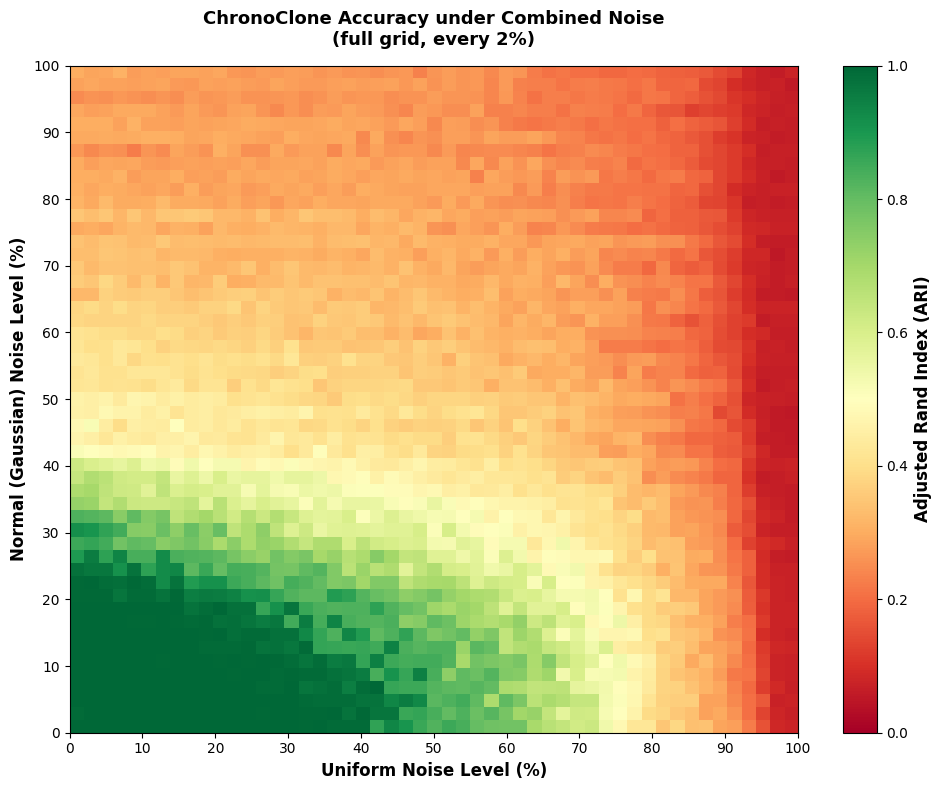

In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(full_combined_grid, cmap='RdYlGn', origin='lower', vmin=0, vmax=1, 
               extent=[0, 100, 0, 100], aspect='auto')
cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Adjusted Rand Index (ARI)", fontsize=12, fontweight='bold')

ax.set_xlabel("Uniform Noise Level (%)", fontsize=12, fontweight='bold')
ax.set_ylabel("Normal (Gaussian) Noise Level (%)", fontsize=12, fontweight='bold')
ax.set_title("ChronoClone Accuracy under Combined Noise\n(full grid, every 2%)", fontsize=13, fontweight='bold', pad=15)

# Add tick marks every 10%
ticks = list(range(0, 101, 10))
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.set_xticklabels([f"{x}" for x in ticks])
ax.set_yticklabels([f"{y}" for y in ticks])

plt.tight_layout()
plt.show()

### Save Results to CSV


In [11]:
# Save single noise results
single_df = pd.DataFrame({
    'noise_pct': all_levels,
    'normal_ari': full_normal_ari,
    'uniform_ari': full_uniform_ari
})
single_df.to_csv('simulated_data/single_noise_ari_results.csv', index=False)
print("Single noise results saved to simulated_data/single_noise_ari_results.csv")

# Save combined noise grid
combined_df = pd.DataFrame(full_combined_grid, 
                           index=[f"Normal_{p}" for p in all_levels_combined],
                           columns=[f"Uniform_{p}" for p in all_levels_combined])
combined_df.to_csv('simulated_data/combined_noise_ari_results.csv')
print("Combined noise grid saved to simulated_data/combined_noise_ari_results.csv")
print(f"Grid shape: {full_combined_grid.shape}")


Single noise results saved to simulated_data/single_noise_ari_results.csv
Combined noise grid saved to simulated_data/combined_noise_ari_results.csv
Grid shape: (51, 51)
